<h1><center><bold>Image Mining <br>
Atelier — Classification supervisée d'images </bold><br><br>
Réalisé par : Aymane Amila <br>
Encadré par : Pr. Abdelouahed Sabri<br>
Master : MLAIM</center></h1>


### 1. Objectifs de l'atelier

Cet atelier a pour but de réaliser toutes les étapes d'un projet de **classification supervisée d'images** :

1. **Préparer et explorer** un jeu de données d'images organisé en deux classes.

    **`car`** : voitures (dossier `DB2C/obj_car`) — **classe positive** pour l'évaluation
    
    **`ship`** : bateaux (dossier `DB2C/obj_ship`).

2. **Extraire des caractéristiques** visuelles à partir de cinq familles de descripteurs.
3. **Entraîner** un classifieur SVM à noyau RBF pour distinguer les voitures des bateaux.
4. **Évaluer** les performances du modèle à l'aide de la matrice de confusion et des métriques de classification.
5. **Comparer** six algorithmes de classification sur les mêmes données.

Ce atelier prolonge le TP CBIR : les **mêmes descripteurs** sont conservés, mais la distance euclidienne de la recherche d'images est remplacée par un **classifieur appris**.
Comme dans le TP CBIR, les descripteurs sont ajoutés progressivement :
1. Couleur RGB : 6 caractéristiques
2. Couleur RGB + histogramme HSV : 32 caractéristiques
3. "+ texture GLCM : 4 caractéristiques
4. "+ texture LBP : 10 caractéristiques
5. "+ forme (moments de Hu) : 7 caractéristiques

### Table des matières
2. Importation des bibliothèques et configuration
3. **Étape A** — Préparation et exploration des images
4. **Étape B** — Extraction des caractéristiques
5. **Étape C** — Apprentissage et prédiction avec SVM RBF
6. **Étape D** — Évaluation du modèle
7. **Étape E** — Comparaison de six algorithmes
8. Conclusion générale


### 2. Importation des bibliothèques et configuration

Vérification de l'environnement :
- Placez le dossier `DB2C/` (contenant `obj_car/` et `obj_ship/`) **dans le même répertoire** que ce notebook, ou modifiez la variable `CHEMIN_BASE` ci-dessous.

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)

import warnings
warnings.filterwarnings('ignore')

# Configuration de l'affichage
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['figure.dpi'] = 100
sns.set_style("whitegrid")

# Graine aléatoire pour la reproductibilité
RANDOM_STATE = 42

print("Toutes les bibliothèques ont été importées avec succès.")

Toutes les bibliothèques ont été importées avec succès.


---
## 3. Étape A — Préparation et exploration des images

### A1. Charger la base

#### Objectif
Charger toutes les images du jeu de données `DB2C`, les convertir en RGB, et comprendre les différentes représentations des pixels.

> OpenCV charge les images en **BGR** (Bleu, Vert, Rouge) par défaut, pas en RGB. Il faut les convertir pour un affichage correct avec Matplotlib et pour calculer les statistiques RGB.

#### Stratégie de chargement

Les images peuvent avoir des dimensions différentes. Pour l'extraction de caractéristiques (statistiques, histogrammes, textures, moments), **il n'est pas nécessaire de redimensionner** les images car chaque méthode produit un vecteur de taille fixe indépendamment de la taille de l'image. Nous conservons donc les dimensions originales.

In [2]:
# ============================================================
# A1 — Chargement des images
# ============================================================

# Chemin vers le jeu de données — à modifier si nécessaire
CHEMIN_BASE = "DB2C"

# Extensions d'images acceptées
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif'}

# Noms des classes et des dossiers correspondants
CLASSES = {
    'car': 'obj_car',   # label 1 (classe positive)
    'ship': 'obj_ship'  # label 0 (classe négative)
}

# Labels numériques
LABEL_MAP = {'car': 1, 'ship': 0}


def charger_images_classe(chemin_dossier):
    """
    Charge toutes les images d'un dossier.
    
    Paramètres :
        chemin_dossier : chemin vers le dossier contenant les images.
    
    Retourne :
        images : liste d'images en format RGB (numpy arrays).
    """
    images = []
    # Trier les noms de fichiers pour un ordre reproductible
    noms_fichiers = sorted(os.listdir(chemin_dossier))
    
    for nom_fichier in noms_fichiers:
        ext = os.path.splitext(nom_fichier)[1].lower()
        if ext not in EXTENSIONS:
            continue
        
        chemin_image = os.path.join(chemin_dossier, nom_fichier)
        # OpenCV charge en BGR
        img_bgr = cv2.imread(chemin_image)
        
        if img_bgr is None:
            print(f"  Attention : impossible de charger '{nom_fichier}', ignorée.")
            continue
        
        # Conversion BGR → RGB pour cohérence
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        images.append(img_rgb)
    
    return images


# Chargement des deux classes
images_car = charger_images_classe(os.path.join(CHEMIN_BASE, CLASSES['car']))
images_ship = charger_images_classe(os.path.join(CHEMIN_BASE, CLASSES['ship']))

print(f"Images 'car' chargées  : {len(images_car)}")
print(f"Images 'ship' chargées : {len(images_ship)}")
print(f"Total                  : {len(images_car) + len(images_ship)}")

Images 'car' chargées  : 400
Images 'ship' chargées : 90
Total                  : 490


### A2. Extraire les deux classes et séparer apprentissage / test

#### Objectif
Construire les listes d'images et d'étiquettes, puis séparer les données en ensemble d'apprentissage (80 %) et ensemble de test (20 %) **avant** l'extraction des caractéristiques.

- **car** → label `1` (classe positive)
- **ship** → label `0` (classe négative)

In [3]:
# ============================================================
# A2 — Création des étiquettes et séparation train/test
# ============================================================

# Toutes les images et leurs étiquettes
toutes_images = images_car + images_ship
toutes_etiquettes = ([1] * len(images_car)) + ([0] * len(images_ship))

# Conversion en array numpy pour les étiquettes
toutes_etiquettes = np.array(toutes_etiquettes)

# Séparation apprentissage / test (80% / 20%)
# stratify assure que les proportions des classes sont conservées
# random_state assure la reproductibilité
indices = np.arange(len(toutes_images))

indices_train, indices_test, y_train, y_test = train_test_split(
    indices,
    toutes_etiquettes,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=toutes_etiquettes
)

# Récupérer les images correspondantes
images_train = [toutes_images[i] for i in indices_train]
images_test = [toutes_images[i] for i in indices_test]

print(f"Séparation réalisée avec random_state={RANDOM_STATE} et stratify activé.")
print(f"  Ensemble d'apprentissage : {len(images_train)} images")
print(f"  Ensemble de test         : {len(images_test)} images")

Séparation réalisée avec random_state=42 et stratify activé.
  Ensemble d'apprentissage : 392 images
  Ensemble de test         : 98 images


### A3. Afficher et expliquer les données

#### Objectif
Visualiser la répartition des données et afficher des exemples d'images de chaque classe.

EXPLORATION DES DONNÉES
Nombre total d'images : 490
  - Classe 'car'  (label 1) : 400 images
  - Classe 'ship' (label 0) : 90 images

Ensemble d'apprentissage : 392 images
  - car  : 320
  - ship : 72
Ensemble de test : 98 images
  - car  : 80
  - ship : 18



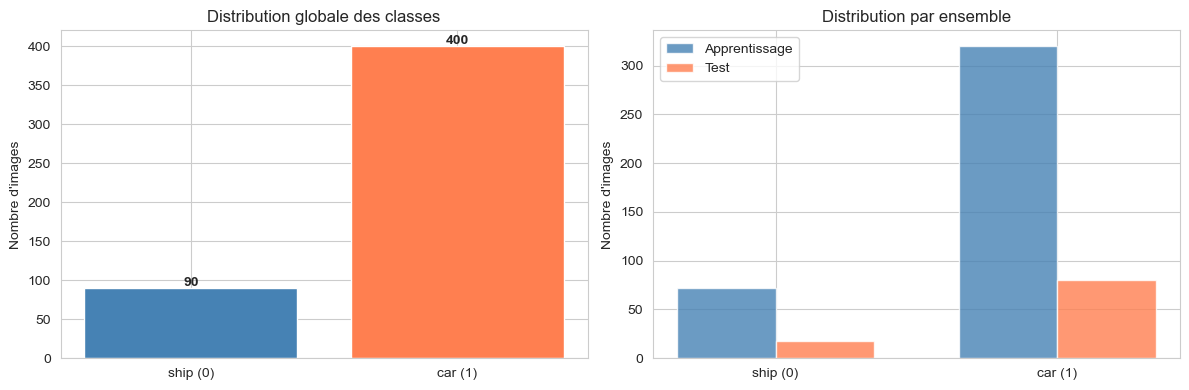

In [4]:
# ============================================================
# A3 — Exploration des données
# ============================================================

# Nombre total d'images
print("=" * 50)
print("EXPLORATION DES DONNÉES")
print("=" * 50)
print(f"Nombre total d'images : {len(toutes_images)}")
print(f"  - Classe 'car'  (label 1) : {len(images_car)} images")
print(f"  - Classe 'ship' (label 0) : {len(images_ship)} images")
print()

# Ensemble d'apprentissage
nb_car_train = np.sum(y_train == 1)
nb_ship_train = np.sum(y_train == 0)
print(f"Ensemble d'apprentissage : {len(y_train)} images")
print(f"  - car  : {nb_car_train}")
print(f"  - ship : {nb_ship_train}")

# Ensemble de test
nb_car_test = np.sum(y_test == 1)
nb_ship_test = np.sum(y_test == 0)
print(f"Ensemble de test : {len(y_test)} images")
print(f"  - car  : {nb_car_test}")
print(f"  - ship : {nb_ship_test}")
print()

# Visualisation de la distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribution globale
classes_noms = ['ship (0)', 'car (1)']
axes[0].bar(classes_noms, [len(images_ship), len(images_car)], color=['steelblue', 'coral'])
axes[0].set_title("Distribution globale des classes")
axes[0].set_ylabel("Nombre d'images")
for i, v in enumerate([len(images_ship), len(images_car)]):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

# Distribution train / test
x = np.arange(2)
largeur = 0.35
axes[1].bar(x - largeur/2, [nb_ship_train, nb_car_train], largeur,
            label='Apprentissage', color='steelblue', alpha=0.8)
axes[1].bar(x + largeur/2, [nb_ship_test, nb_car_test], largeur,
            label='Test', color='coral', alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(classes_noms)
axes[1].set_title("Distribution par ensemble")
axes[1].set_ylabel("Nombre d'images")
axes[1].legend()

plt.tight_layout()
plt.show()

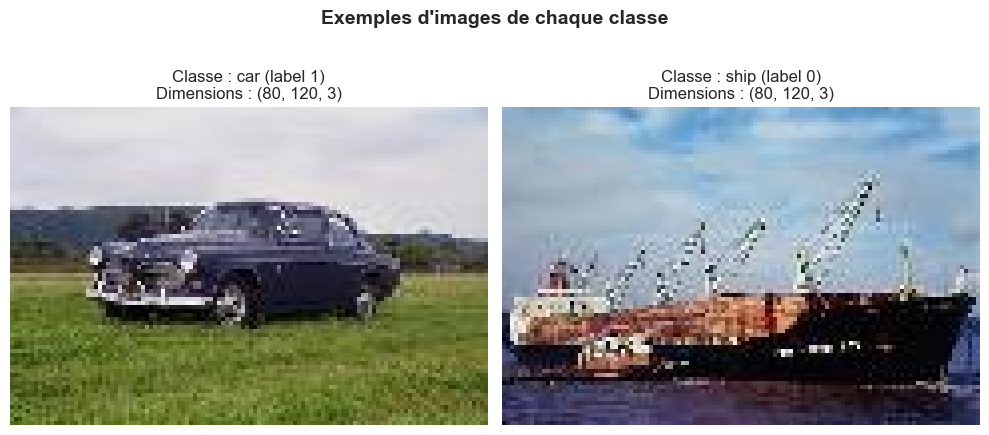

In [5]:
# Affichage d'un exemple de chaque classe
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Trouver un exemple de chaque classe dans l'ensemble d'apprentissage
idx_car = np.where(y_train == 1)[0][0]
idx_ship = np.where(y_train == 0)[0][0]

axes[0].imshow(images_train[idx_car])
axes[0].set_title(f"Classe : car (label 1)\nDimensions : {images_train[idx_car].shape}")
axes[0].axis('off')

axes[1].imshow(images_train[idx_ship])
axes[1].set_title(f"Classe : ship (label 0)\nDimensions : {images_train[idx_ship].shape}")
axes[1].axis('off')

plt.suptitle("Exemples d'images de chaque classe", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Réponse A3 — Exploration des données et intérêt de la séparation apprentissage/test

**Ce que montrent les dimensions des ensembles :**
- Le jeu de données est **déséquilibré** : la classe *car* contient beaucoup plus d'images que la classe *ship*. Cela signifie qu'un modèle naïf qui prédirait toujours *car* obtiendrait déjà une accuracy relativement élevée sans avoir rien appris de pertinent.
- La séparation 80/20 répartit les images en un ensemble d'apprentissage majoritaire et un ensemble de test plus petit, ce qui est un partage standard en Machine Learning.

**Pourquoi séparer les données d'apprentissage des données de test ?**

Le but d'un classifieur n'est pas de reconnaître les images qu'il a déjà vues, mais de **généraliser** à de nouvelles images. Si l'on évaluait le modèle sur les images qui ont servi à l'entraîner, on mesurerait surtout sa capacité à mémoriser (un KNN ou un arbre profond obtiennent presque 100 % sur leurs propres données), et l'on obtiendrait une estimation **trop optimiste** de la performance réelle. L'ensemble de test doit donc rester **totalement indépendant** : il n'est utilisé ni pour entraîner le modèle, ni pour ajuster le normalisateur, ni pour choisir les paramètres ; il sert uniquement à mesurer, à la fin, la performance sur des images « inconnues ». 

---
## 4. Étape B — Extraction des caractéristiques

### B1. Implémenter les cinq méthodes de descripteurs

Chaque fonction reçoit une image RGB (numpy array, entiers 0–255) et retourne un vecteur numérique 1D.

#### B1.1. Statistiques de couleur RGB

Pour chaque canal (Rouge, Vert, Bleu), on calcule la **moyenne** et l'**écart-type** des valeurs des pixels.

- La **moyenne** indique l'intensité globale du canal (ex : une image de ciel bleu aura une moyenne élevée sur le canal Bleu).
- L'**écart-type** mesure la dispersion des valeurs, donc la variabilité des couleurs dans l'image.

Le vecteur résultant contient **6 valeurs** : `[moy_R, et_R, moy_G, et_G, moy_B, et_B]`.

In [6]:
# ============================================================
# B1.1 — Statistiques de couleur RGB
# ============================================================

def extraire_stats_rgb(image_rgb):
    """
    Calcule la moyenne et l'écart-type de chaque canal RGB.
    
    Paramètres :
        image_rgb : image en RGB (numpy array, uint8).
    
    Retourne :
        vecteur de 6 valeurs : [moy_R, et_R, moy_G, et_G, moy_B, et_B].
    """
    features = []
    for canal in range(3):  # R=0, G=1, B=2
        pixels = image_rgb[:, :, canal].astype(np.float64)
        features.append(np.mean(pixels))
        features.append(np.std(pixels))
    return np.array(features, dtype=np.float64)

# Test sur un exemple
test_rgb = extraire_stats_rgb(images_train[0])
print(f"Statistiques RGB — dimension du vecteur : {test_rgb.shape[0]}")

Statistiques RGB — dimension du vecteur : 6


#### B1.2. Histogramme HSV

L'image est convertie dans l'espace **HSV** (Teinte, Saturation, Valeur), qui sépare l'information de couleur (H) de l'information de luminosité (V).

On calcule un **histogramme 3D** avec les dimensions suivantes :
- **H** (Teinte) : 8 bins
- **S** (Saturation) : 2 bins
- **V** (Valeur) : 2 bins

L'histogramme est **normalisé** (somme = 1) pour que les vecteurs soient comparables quelle que soit la taille de l'image, puis **aplati** en un vecteur 1D de taille **8 × 2 × 2 = 32**.

In [7]:
# ============================================================
# B1.2 — Histogramme HSV
# ============================================================

# Paramètres de l'histogramme HSV
BINS_HSV = [8, 2, 2]
RANGES_HSV = [0, 180, 0, 256, 0, 256]  # Plages OpenCV pour H, S, V


def extraire_hist_hsv(image_rgb):
    """
    Calcule l'histogramme 3D normalisé dans l'espace HSV.
    
    Paramètres :
        image_rgb : image en RGB (numpy array, uint8).
    
    Retourne :
        vecteur 1D de taille 32 (8×2×2).
    """
    # Conversion RGB → HSV
    image_hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
    
    # Calcul de l'histogramme 3D
    hist = cv2.calcHist(
        [image_hsv],
        [0, 1, 2],        # Les 3 canaux
        None,              # Pas de masque
        BINS_HSV,          # Nombre de bins par canal
        RANGES_HSV         # Plages de valeurs
    )
    
    # Normalisation (somme = 1)
    hist = cv2.normalize(hist, hist).flatten()
    return hist.astype(np.float64)


# Test sur un exemple
test_hsv = extraire_hist_hsv(images_train[0])
print(f"Histogramme HSV — dimension du vecteur : {test_hsv.shape[0]}")

Histogramme HSV — dimension du vecteur : 32


#### B1.3. Caractéristiques de texture GLCM

La **matrice de co-occurrence des niveaux de gris** (GLCM) décrit la fréquence avec laquelle des paires de pixels voisins prennent certaines combinaisons de niveaux de gris. Elle capture des informations de **texture**.

On extrait les propriétés suivantes :
- **Contrast** : mesure les variations locales d'intensité. Une texture rugueuse a un contraste élevé.
- **Homogeneity** : inversement liée au contraste. Élevée pour des textures uniformes.
- **Energy** : mesure l'uniformité de la distribution. Élevée si peu de paires de niveaux de gris dominent.
- **Correlation** : mesure la corrélation linéaire entre pixels voisins.

Paramètres :
- Distances : `[1]` (pixels adjacents)
- Angles : `[0]` (directions)
- Niveaux de gris : image quantifiée sur **64 niveaux** pour limiter la taille de la matrice.

Le vecteur contient **4 propriétés × 1 distance × 1 angles = 4 valeurs**.

In [8]:
# ============================================================
# B1.3 — Caractéristiques de texture GLCM
# ============================================================

# Paramètres GLCM
GLCM_DISTANCES = [1]
GLCM_ANGLES = [0]
GLCM_NIVEAUX = 64  # Quantification sur 64 niveaux
GLCM_PROPRIETES = ['contrast','homogeneity', 'energy', 'correlation']


def extraire_glcm(image_rgb):
    """
    Calcule les propriétés de texture GLCM.
    
    Paramètres :
        image_rgb : image en RGB (numpy array, uint8).
    
    Retourne :
        vecteur 1D de taille 4 (4 propriétés × 1 angle).
    """
    # Conversion en niveaux de gris
    image_gris = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    
    # Quantification sur GLCM_NIVEAUX niveaux
    image_quant = (image_gris / 256 * GLCM_NIVEAUX).astype(np.uint8)
    
    # Calcul de la matrice GLCM
    glcm = graycomatrix(
        image_quant,
        distances=GLCM_DISTANCES,
        angles=GLCM_ANGLES,
        levels=GLCM_NIVEAUX,
        symmetric=True,
        normed=True
    )
    
    # Extraction des propriétés
    features = []
    for prop in GLCM_PROPRIETES:
        valeurs = graycoprops(glcm, prop)  # shape: (nb_distances, nb_angles)
        features.extend(valeurs.flatten())
    
    return np.array(features, dtype=np.float64)


# Test sur un exemple
test_glcm = extraire_glcm(images_train[0])
print(f"GLCM — dimension du vecteur : {test_glcm.shape[0]}")

GLCM — dimension du vecteur : 4


#### B1.4. Local Binary Patterns (LBP)

Le **LBP** est un descripteur de texture locale. Pour chaque pixel, on compare sa valeur avec ses voisins disposés sur un cercle de rayon donné :
- Si un voisin a une valeur supérieure ou égale au pixel central, on note `1`, sinon `0`.
- Les bits obtenus forment un code binaire, le *pattern* LBP du pixel.

L'histogramme de ces codes résume la distribution des motifs de texture dans l'image. Un histogramme LBP permet par exemple de distinguer une surface lisse (peu de patterns différents) d'une surface texturée.

Paramètres :
- **Points** : 8 (nombre de voisins sur le cercle)
- **Rayon** : 1 pixels
- **Méthode** : `'uniform'` (regroupe les patterns ayant au plus 2 transitions 0→1 ou 1→0, ce qui réduit le nombre de bins)

Avec la méthode *uniform* et 8 points, le nombre de bins est **P + 2 = 10**.

In [9]:
# ============================================================
# B1.4 — Local Binary Patterns (LBP)
# ============================================================

# Paramètres LBP
LBP_POINTS = 8
LBP_RAYON = 1
LBP_METHODE = 'uniform'
LBP_N_BINS = LBP_POINTS + 2  # 10 features


def extraire_lbp(image_rgb):
    """
    Calcule l'histogramme LBP normalisé.
    
    Paramètres :
        image_rgb : image en RGB (numpy array, uint8).
    
    Retourne :
        vecteur 1D de taille 10.
    """
    # Conversion en niveaux de gris
    image_gris = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    
    # Calcul des codes LBP
    lbp = local_binary_pattern(image_gris, LBP_POINTS, LBP_RAYON, method=LBP_METHODE)
    
    # Histogramme des codes LBP
    hist, _ = np.histogram(lbp, bins=LBP_N_BINS, range=(0, LBP_N_BINS), density=True)
    
    return hist.astype(np.float64)


# Test sur un exemple
test_lbp = extraire_lbp(images_train[0])
print(f"LBP — dimension du vecteur : {test_lbp.shape[0]}")

LBP — dimension du vecteur : 10


#### B1.5. Moments de Hu

Les **moments de Hu** sont un ensemble de 7 valeurs calculées à partir des moments géométriques de l'image en niveaux de gris. Ils ont la propriété d'être **invariants** par translation, rotation et changement d'échelle, ce qui les rend utiles pour décrire la **forme** globale d'un objet.

Les valeurs des moments de Hu peuvent varier sur plusieurs ordres de grandeur. On applique une **transformation logarithmique signée** pour stabiliser les valeurs :

$$h_i' = -\text{sign}(h_i) \cdot \log_{10}(|h_i| + \varepsilon)$$

où $\varepsilon$ est une petite constante pour éviter le logarithme de zéro.

In [10]:
# ============================================================
# B1.5 — Moments de Hu
# ============================================================

def extraire_moments_hu(image_rgb):
    """
    Calcule les 7 moments de Hu avec transformation logarithmique signée.
    
    Paramètres :
        image_rgb : image en RGB (numpy array, uint8).
    
    Retourne :
        vecteur 1D de taille 7.
    """
    # Conversion en niveaux de gris
    image_gris = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    
    # Calcul des moments géométriques
    moments = cv2.moments(image_gris)
    
    # Calcul des moments de Hu (7 valeurs)
    hu = cv2.HuMoments(moments).flatten()
    
    # Transformation logarithmique signée stable
    epsilon = 1e-12
    hu_log = -np.sign(hu) * np.log10(np.abs(hu) + epsilon)
    
    # Vérification : remplacer les éventuelles valeurs non finies
    hu_log = np.where(np.isfinite(hu_log), hu_log, 0.0)
    
    return hu_log.astype(np.float64)


# Test sur un exemple
test_hu = extraire_moments_hu(images_train[0])
print(f"Moments de Hu — dimension du vecteur : {test_hu.shape[0]}")

Moments de Hu — dimension du vecteur : 7


#### B1.6. Construire un vecteur combiné de caractéristiques

Le vecteur final concatène les cinq familles.

In [11]:
# ============================================================
# B1.6 — Vecteur combiné
# ============================================================

def extraire_caracteristiques(image_rgb):
    """
    Extrait et concatène les 5 familles de caractéristiques.
    
    Paramètres :
        image_rgb : image en RGB (numpy array, uint8).
    
    Retourne :
        vecteur 1D de taille 59.
    """
    f_rgb = extraire_stats_rgb(image_rgb)
    f_hsv = extraire_hist_hsv(image_rgb)
    f_glcm = extraire_glcm(image_rgb)
    f_lbp = extraire_lbp(image_rgb)
    f_hu = extraire_moments_hu(image_rgb)
    
    # Concaténation
    vecteur = np.concatenate([f_rgb, f_hsv, f_glcm, f_lbp, f_hu])
    
    return vecteur


# Test sur un exemple
test_complet = extraire_caracteristiques(images_train[0])
print(f"Vecteur combiné — dimension : {test_complet.shape[0]}")
print(f"  - RGB  : {extraire_stats_rgb(images_train[0]).shape[0]}")
print(f"  - HSV  : {extraire_hist_hsv(images_train[0]).shape[0]}")
print(f"  - GLCM : {extraire_glcm(images_train[0]).shape[0]}")
print(f"  - LBP  : {extraire_lbp(images_train[0]).shape[0]}")
print(f"  - Hu   : {extraire_moments_hu(images_train[0]).shape[0]}")
print(f"Toutes les valeurs sont finies : {np.all(np.isfinite(test_complet))}")

Vecteur combiné — dimension : 59
  - RGB  : 6
  - HSV  : 32
  - GLCM : 4
  - LBP  : 10
  - Hu   : 7
Toutes les valeurs sont finies : True


### B2. Construire les matrices de caractéristiques

Appliquer l'extraction de caractéristiques à toutes les images d'apprentissage et de test pour obtenir les matrices `X_train` et `X_test`.

In [12]:
# ============================================================
# B2 — Construction des matrices X_train et X_test
# ============================================================

print("Extraction des caractéristiques en cours...")
print()

# Apprentissage
X_train = np.array([extraire_caracteristiques(img) for img in images_train])
print(f"X_train terminé : {X_train.shape}")

# Test
X_test = np.array([extraire_caracteristiques(img) for img in images_test])
print(f"X_test terminé  : {X_test.shape}")

print()
print("=" * 50)
print("VÉRIFICATION DES DIMENSIONS")
print("=" * 50)
print(f"X_train : {X_train.shape}  (lignes={X_train.shape[0]}, colonnes={X_train.shape[1]})")
print(f"y_train : {y_train.shape}  (longueur={y_train.shape[0]})")
print(f"X_test  : {X_test.shape}  (lignes={X_test.shape[0]}, colonnes={X_test.shape[1]})")
print(f"y_test  : {y_test.shape}  (longueur={y_test.shape[0]})")
print()

# Vérifications de cohérence
assert X_train.shape[0] == y_train.shape[0], "Incohérence X_train / y_train !"
assert X_test.shape[0] == y_test.shape[0], "Incohérence X_test / y_test !"
assert X_train.shape[1] == X_test.shape[1], "Nombre de colonnes différent entre train et test !"
assert np.all(np.isfinite(X_train)), "X_train contient des valeurs non finies !"
assert np.all(np.isfinite(X_test)), "X_test contient des valeurs non finies !"

print("✓ Le nombre de lignes de X_train correspond à y_train.")
print("✓ Le nombre de lignes de X_test correspond à y_test.")
print(f"✓ Le nombre de colonnes est identique : {X_train.shape[1]}.")
print("✓ Toutes les valeurs sont finies (pas de NaN ni d'infini).")

Extraction des caractéristiques en cours...

X_train terminé : (392, 59)
X_test terminé  : (98, 59)

VÉRIFICATION DES DIMENSIONS
X_train : (392, 59)  (lignes=392, colonnes=59)
y_train : (392,)  (longueur=392)
X_test  : (98, 59)  (lignes=98, colonnes=59)
y_test  : (98,)  (longueur=98)

✓ Le nombre de lignes de X_train correspond à y_train.
✓ Le nombre de lignes de X_test correspond à y_test.
✓ Le nombre de colonnes est identique : 59.
✓ Toutes les valeurs sont finies (pas de NaN ni d'infini).


### Réponse B2 — Dimensions des matrices de caractéristiques

**Chaque ligne représente une image :** la ligne $i$ de `X_train` contient le vecteur de caractéristiques de la $i$-ème image d'apprentissage. Le nombre de lignes correspond donc au nombre d'images dans l'ensemble.

**Chaque colonne représente une caractéristique numérique :** les 59 colonnes correspondent aux 5 familles de descripteurs concaténées (6 RGB + 32 HSV + 4 GLCM + 10 LBP + 7 Hu). Chaque colonne mesure un aspect spécifique de l'image.

**Le nombre de colonnes doit être identique entre apprentissage et test :** les classifieurs apprennent une relation entre les caractéristiques (colonnes) et les étiquettes. Si le test avait un nombre de colonnes différent, le modèle ne pourrait pas s'appliquer — les dimensions seraient incompatibles.

**Les étiquettes ne font pas partie des caractéristiques :** les vecteurs `y_train` et `y_test` sont séparés de `X_train` et `X_test`. Si on incluait l'étiquette comme une caractéristique, le modèle « tricherait » en utilisant directement la réponse pour prédire, ce qui rendrait l'évaluation sans valeur.

### Réponse B3 — Pourquoi utiliser des vecteurs de caractéristiques plutôt que des images brutes ?

**Pourquoi transformer les images ?**
Les classifieurs classiques (SVM, KNN, arbre de décision) travaillent sur des **vecteurs numériques de dimension fixe**. Or, les images brutes sont des matrices 2D (ou 3D avec la couleur) de dimensions potentiellement différentes. Il faut donc les transformer en une représentation numérique exploitable.

**Ce que résument les cinq familles de caractéristiques :**
- **Statistiques RGB** : résument l'information de couleur globale (intensité moyenne et variabilité de chaque canal).
- **Histogramme HSV** : capture la distribution des couleurs et de la luminosité dans un espace perceptuellement plus pertinent que RGB.
- **GLCM** : décrit les motifs de texture en analysant les relations entre pixels voisins (contraste, homogénéité, etc.).
- **LBP** : capture les micro-textures locales (bords, coins, surfaces planes) par un codage binaire des voisinages.
- **Moments de Hu** : décrivent la forme globale de l'objet de manière invariante aux transformations géométriques.

**Réduction de dimension :**
Une image de 100×100 pixels en couleur contient 30 000 valeurs. Notre vecteur de caractéristiques n'en contient que 59, soit une réduction considérable. Cette compression facilite l'apprentissage et réduit le temps de calcul.

**Perte d'information :**
Cette compression a un coût : les caractéristiques résument l'image mais ne la décrivent pas entièrement. Des détails fins, des relations spatiales ou des motifs complexes peuvent être perdus. Les performances du classifieur dépendent directement de la **qualité et de la pertinence** des caractéristiques choisies.

**Dans le contexte de cet atelier :**
L'extraction manuelle de caractéristiques permet de comprendre comment différentes propriétés visuelles contribuent à la classification. Cependant, il ne faut pas affirmer que cette approche est systématiquement supérieure à l'apprentissage direct sur les pixels : les réseaux de neurones profonds, par exemple, apprennent automatiquement des caractéristiques à partir des données brutes et obtiennent souvent de meilleurs résultats sur de grands jeux de données.

---
## 5. Étape C — Apprentissage et prédiction avec SVM RBF

### C1. Entraîner un SVM avec noyau RBF

#### Objectif
Entraîner un classifieur SVM à noyau RBF en utilisant un pipeline scikit-learn qui standardise les caractéristiques puis applique le classifieur. Le `StandardScaler` est ajusté **uniquement sur les données d'apprentissage**.

In [13]:
# ============================================================
# C1 — Apprentissage du SVM RBF
# ============================================================

# Pipeline : StandardScaler + SVM RBF
pipeline_svm_rbf = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', random_state=RANDOM_STATE))
])

# Apprentissage — le scaler est ajusté uniquement sur X_train
pipeline_svm_rbf.fit(X_train, y_train)

print("Apprentissage du SVM RBF terminé.")
print(f"  Noyau        : rbf")
print(f"  Paramètre C  : {pipeline_svm_rbf.named_steps['svm'].C}")
print(f"  Paramètre γ  : {pipeline_svm_rbf.named_steps['svm'].gamma}")

Apprentissage du SVM RBF terminé.
  Noyau        : rbf
  Paramètre C  : 1.0
  Paramètre γ  : scale


### C2. Prédire la classe d'une image de test
Sélectionner une image de test (indice fixe pour la reproductibilité), afficher sa vraie classe et sa classe prédite.

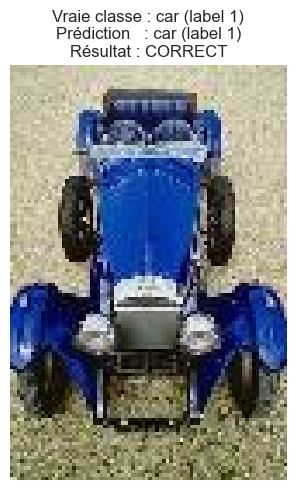

Image de test n°5
  Vraie classe : car (label 1)
  Prédiction   : car (label 1)
  Résultat     : CORRECT


In [14]:
# ============================================================
# C2 — Prédiction individuelle
# ============================================================

# On choisit l'image à l'indice 5 du jeu de test (choix fixe, reproductible)
IDX_EXEMPLE = 5

image_exemple = images_test[IDX_EXEMPLE]
vraie_etiquette = y_test[IDX_EXEMPLE]
vecteur_exemple = X_test[IDX_EXEMPLE].reshape(1, -1)

# Prédiction
etiquette_predite = pipeline_svm_rbf.predict(vecteur_exemple)[0]

# Noms des classes
noms_classes = {0: 'ship', 1: 'car'}
correct = "CORRECT" if etiquette_predite == vraie_etiquette else "INCORRECT"

# Affichage de l'image
plt.figure(figsize=(5, 5))
plt.imshow(image_exemple)
plt.title(
    f"Vraie classe : {noms_classes[vraie_etiquette]} (label {vraie_etiquette})\n"
    f"Prédiction   : {noms_classes[etiquette_predite]} (label {etiquette_predite})\n"
    f"Résultat : {correct}",
    fontsize=12
)
plt.axis('off')
plt.tight_layout()
plt.show()

print(f"Image de test n°{IDX_EXEMPLE}")
print(f"  Vraie classe : {noms_classes[vraie_etiquette]} (label {vraie_etiquette})")
print(f"  Prédiction   : {noms_classes[etiquette_predite]} (label {etiquette_predite})")
print(f"  Résultat     : {correct}")

### Réponse C3 — Différence entre apprentissage et prédiction

**`fit()` — L'apprentissage :**
La méthode `fit(X_train, y_train)` est l'étape d'apprentissage. Le modèle analyse les vecteurs de caractéristiques et leurs étiquettes associées pour **apprendre une frontière de décision** séparant les deux classes dans l'espace des caractéristiques. Pour le SVM RBF, cela consiste à trouver un hyperplan (transformé par le noyau RBF dans un espace de dimension supérieure) qui maximise la marge entre les classes.

**`predict()` — La prédiction :**
La méthode `predict(X_test)` utilise la frontière de décision apprise pendant `fit()` pour **attribuer une classe** à chaque nouveau vecteur de caractéristiques. Le modèle ne modifie pas ses paramètres internes lors de la prédiction.

**Pourquoi l'image test ne doit pas servir à apprendre ?**
Si les images de test participent à l'apprentissage, le modèle peut les mémoriser et obtenir un score artificiellement élevé. L'évaluation ne mesurerait plus la capacité de **généralisation** mais la capacité de **mémorisation**.

**Pourquoi une prédiction individuelle ne suffit pas ?**
Une seule image peut être facile ou difficile à classer, indépendamment de la qualité du modèle. Il faut évaluer les prédictions sur **tout l'ensemble de test** pour obtenir des statistiques significatives (accuracy, precision, recall, etc.).

---
## 6. Étape D — Évaluation du modèle

### D1. Matrice de confusion

#### Objectif
Prédire les étiquettes de toutes les images de test avec le SVM RBF et analyser les erreurs à l'aide de la matrice de confusion.

Pour la classe positive **car** (label 1).

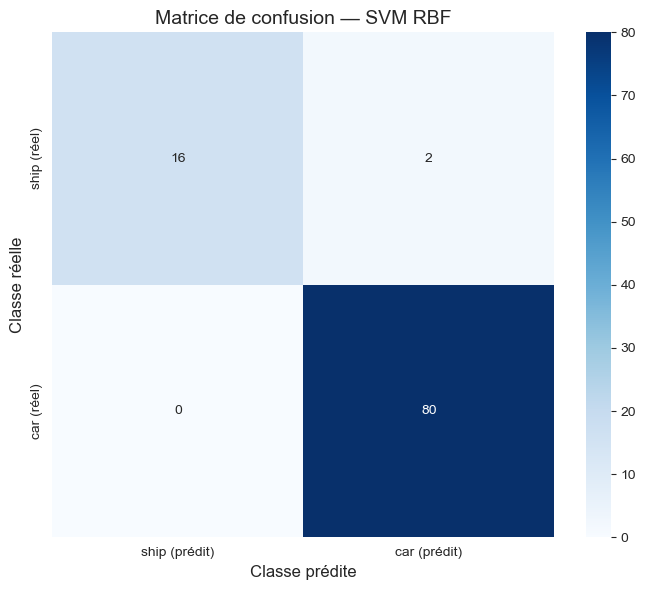

Interprétation (car = classe positive) :
  TP (voiture reconnue comme voiture)   : 80
  TN (bateau reconnu comme bateau)       : 16
  FP (bateau prédit comme voiture)       : 2
  FN (voiture prédite comme bateau)      : 0


In [15]:
# ============================================================
# D1 — Matrice de confusion
# ============================================================

# Prédictions sur tout l'ensemble de test
y_pred = pipeline_svm_rbf.predict(X_test)

# Matrice de confusion avec l'ordre des classes [0, 1] = [ship, car]
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Affichage graphique de la matrice de confusion
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ship (prédit)', 'car (prédit)'],
    yticklabels=['ship (réel)', 'car (réel)']
)
plt.xlabel('Classe prédite', fontsize=12)
plt.ylabel('Classe réelle', fontsize=12)
plt.title('Matrice de confusion — SVM RBF', fontsize=14)
plt.tight_layout()
plt.show()

# Extraction des valeurs (pour car comme classe positive, label=1)
TN, FP, FN, TP = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]

print(f"Interprétation (car = classe positive) :")
print(f"  TP (voiture reconnue comme voiture)   : {TP}")
print(f"  TN (bateau reconnu comme bateau)       : {TN}")
print(f"  FP (bateau prédit comme voiture)       : {FP}")
print(f"  FN (voiture prédite comme bateau)      : {FN}")

Les valeurs affichées ci-dessus proviennent des prédictions réelles du SVM RBF sur le jeu de test. L'analyse de ces quatre quantités permet de comprendre **où** le modèle se trompe et sur **quelle classe** il est le moins performant.

### D2. Rapport de classification et métriques
Calculer et interpréter les métriques de classification : accuracy, precision, recall, F1-score pour chaque classe et les moyennes.

In [16]:
# ============================================================
# D2 — Rapport de classification et métriques
# ============================================================

# Rapport complet
print("=" * 60)
print("RAPPORT DE CLASSIFICATION — SVM RBF")
print("=" * 60)
print()
rapport = classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=['ship (0)', 'car (1)'],
    zero_division=0
)
print(rapport)

# Métriques calculées explicitement
print("=" * 60)
print("MÉTRIQUES DÉTAILLÉES")
print("=" * 60)

# Accuracy globale
acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy globale : {acc:.4f}")

# Métriques par classe pour car (classe positive, label 1)
prec_car = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
rec_car = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1_car = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
print(f"\nClasse car (positive) :")
print(f"  Precision : {prec_car:.4f}")
print(f"  Recall    : {rec_car:.4f}")
print(f"  F1-score  : {f1_car:.4f}")

# Métriques par classe pour ship (label 0)
prec_ship = precision_score(y_test, y_pred, pos_label=0, zero_division=0)
rec_ship = recall_score(y_test, y_pred, pos_label=0, zero_division=0)
f1_ship = f1_score(y_test, y_pred, pos_label=0, zero_division=0)
print(f"\nClasse ship (négative) :")
print(f"  Precision : {prec_ship:.4f}")
print(f"  Recall    : {rec_ship:.4f}")
print(f"  F1-score  : {f1_ship:.4f}")

# Moyennes
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
print(f"\nMacro average :")
print(f"  Precision : {prec_macro:.4f}")
print(f"  Recall    : {rec_macro:.4f}")
print(f"  F1-score  : {f1_macro:.4f}")

prec_weighted = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec_weighted = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)
print(f"\nWeighted average :")
print(f"  Precision : {prec_weighted:.4f}")
print(f"  Recall    : {rec_weighted:.4f}")
print(f"  F1-score  : {f1_weighted:.4f}")

# Micro average
prec_micro = precision_score(y_test, y_pred, average='micro', zero_division=0)
rec_micro = recall_score(y_test, y_pred, average='micro', zero_division=0)
f1_micro = f1_score(y_test, y_pred, average='micro', zero_division=0)
print(f"\nMicro average :")
print(f"  Precision : {prec_micro:.4f}")
print(f"  Recall    : {rec_micro:.4f}")
print(f"  F1-score  : {f1_micro:.4f}")
print(f"\nNote : en classification binaire mono-label à deux classes,")
print(f"la micro-precision, le micro-recall et le micro-F1 coïncident")
print(f"tous avec l'accuracy ({acc:.4f}).")

RAPPORT DE CLASSIFICATION — SVM RBF

              precision    recall  f1-score   support

    ship (0)       1.00      0.89      0.94        18
     car (1)       0.98      1.00      0.99        80

    accuracy                           0.98        98
   macro avg       0.99      0.94      0.96        98
weighted avg       0.98      0.98      0.98        98

MÉTRIQUES DÉTAILLÉES

Accuracy globale : 0.9796

Classe car (positive) :
  Precision : 0.9756
  Recall    : 1.0000
  F1-score  : 0.9877

Classe ship (négative) :
  Precision : 1.0000
  Recall    : 0.8889
  F1-score  : 0.9412

Macro average :
  Precision : 0.9878
  Recall    : 0.9444
  F1-score  : 0.9644

Weighted average :
  Precision : 0.9801
  Recall    : 0.9796
  F1-score  : 0.9791

Micro average :
  Precision : 0.9796
  Recall    : 0.9796
  F1-score  : 0.9796

Note : en classification binaire mono-label à deux classes,
la micro-precision, le micro-recall et le micro-F1 coïncident
tous avec l'accuracy (0.9796).


### Réponse D2 — Lecture des métriques de classification

**Définitions des métriques (illustrées avec la classe *car* comme positive) :**

- **Precision (précision)** : parmi toutes les images **prédites** comme *car*, quelle proportion est **réellement** *car* ?
  $$\text{Precision} = \frac{TP}{TP + FP}$$
  Une precision élevée signifie que le modèle fait peu de fausses alertes.

- **Recall (rappel)** : parmi toutes les images **réellement** *car*, quelle proportion est **correctement reconnue** ?
  $$\text{Recall} = \frac{TP}{TP + FN}$$
  Un recall élevé signifie que le modèle manque peu de voitures.

- **F1-score** : moyenne harmonique de la precision et du recall. C'est un compromis entre les deux :
  $$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Accuracy** : proportion totale d'images **correctement classées** (toutes classes confondues) :
  $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

**Différence entre les moyennes :**
- **Macro average** : moyenne simple des métriques des deux classes, sans pondération. Elle donne autant d'importance à chaque classe, même minoritaire.
- **Weighted average** : moyenne pondérée par le nombre d'exemples dans chaque classe. Elle reflète mieux la performance globale quand les classes sont déséquilibrées.
- **Micro average** : en classification binaire mono-label avec deux classes, la micro-precision, le micro-recall et le micro-F1 coïncident tous avec l'accuracy. Cela s'explique par le fait que chaque image reçoit une seule étiquette et que TP + FP = TP + FN = nombre total d'exemples prédits/réels pour l'ensemble des classes.

### Réponse D3 — Une bonne accuracy garantit-elle une bonne reconnaissance des deux classes ?

**Non, pas nécessairement.**

**Pourquoi l'accuracy peut être trompeuse ?**
L'accuracy mesure la proportion globale de bonnes prédictions. Dans un jeu de données **déséquilibré** (comme le nôtre, avec beaucoup plus de voitures que de bateaux), un modèle pourrait atteindre une accuracy élevée simplement en prédisant toujours la classe majoritaire (*car*), sans jamais reconnaître correctement un seul bateau.

**Ce que montrent les résultats obtenus :**
Les métriques calculées ci-dessus montre que même si l'accuracy est élevée, le recall de la classe 'ship' est nettement plus faible, cela signifie que le modèle a plus de difficulté à reconnaître cette classe. La comparaison entre macro average et weighted average permet de voir l'effet du déséquilibre des classes sur la performance perçue.

**C'est pour ça on compléte avec d'autres métriques :**
- La **matrice de confusion** permet de voir les erreurs classe par classe.
- La **precision** révèle si les prédictions positives sont fiables.
- Le **recall** révèle si les exemples positifs sont bien détectés.
- Le **F1-score** combine les deux pour une vue équilibrée.
- La **macro average** donne un poids égal à chaque classe, ce qui met en évidence les problèmes sur les classes minoritaires.

---
## 7. Étape E — Comparaison de six algorithmes

### E1. Entraîner et comparer les six modèles

#### Objectif
Comparer six algorithmes de classification en utilisant **exactement les mêmes données** (même découpage, mêmes caractéristiques, mêmes étiquettes) :

1. SVM avec noyau RBF
2. SVM avec noyau linéaire
3. SVM avec noyau sigmoïde
4. KNN avec k = 3
5. KNN avec k = 5
6. Arbre de décision

Un `StandardScaler` est utilisé dans un pipeline pour les SVM et les KNN. L'arbre de décision n'en a pas besoin car il est invariant aux transformations monotones des caractéristiques.

In [17]:
# ============================================================
# E1 — Entraînement et comparaison des six modèles
# ============================================================
import pandas as pd

# Définition des six modèles dans des pipelines
modeles = {
    'SVM RBF': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf',class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    'SVM linéaire': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='linear', random_state=RANDOM_STATE))
    ]),
    'SVM sigmoïde': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='sigmoid', random_state=RANDOM_STATE))
    ]),
    'KNN (k=3)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=3))
    ]),
    'KNN (k=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Arbre de décision': DecisionTreeClassifier(
        random_state=RANDOM_STATE
    )
}

# Entraînement et évaluation
resultats = {}
resultats_details = {}

for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    y_pred_m = modele.predict(X_test)

    resultats[nom] = accuracy_score(y_test, y_pred_m)

    resultats_details[nom] = {
        'Accuracy': accuracy_score(y_test, y_pred_m),
        'Precision macro': precision_score(
            y_test, y_pred_m, average='macro', zero_division=0
        ),
        'Recall macro': recall_score(
            y_test, y_pred_m, average='macro', zero_division=0
        ),
        'F1 macro': f1_score(
            y_test, y_pred_m, average='macro', zero_division=0
        )
    }

print()
print("=" * 50)
print("TABLEAU COMPARATIF DES SIX ALGORITHMES")
print("=" * 50)
tableau_comparatif = pd.DataFrame(resultats_details).T
display(tableau_comparatif.sort_values('Accuracy', ascending=False))


# Identification du meilleur et du moins performant
meilleur_nom, meilleur_acc = max(resultats.items(), key=lambda x: x[1])
pire_nom, pire_acc = min(resultats.items(), key=lambda x: x[1])

# Vérifier les ex-aequo
meilleurs = [nom for nom, acc_val in resultats.items() if acc_val == meilleur_acc]
pires = [nom for nom, acc_val in resultats.items() if acc_val == pire_acc]

print()
if len(meilleurs) > 1:
    print(f"Meilleur(s)  : {', '.join(meilleurs)} — Accuracy : {meilleur_acc:.4f}")
else:
    print(f"Meilleur modèle  : {meilleur_nom} — Accuracy : {meilleur_acc:.4f}")

if len(pires) > 1:
    print(f"Moins bon(s)  : {', '.join(pires)} — Accuracy : {pire_acc:.4f}")
else:
    print(f"Moins bon modèle : {pire_nom} — Accuracy : {pire_acc:.4f}")


TABLEAU COMPARATIF DES SIX ALGORITHMES


,Accuracy,Precision macro,Recall macro,F1 macro
SVM RBF,0.979592,0.965972,0.965972,0.965972
KNN (k=3),0.979592,0.965972,0.965972,0.965972
KNN (k=5),0.969388,0.941039,0.959722,0.950025
SVM linéaire,0.959184,0.931944,0.931944,0.931944
SVM sigmoïde,0.959184,0.931944,0.931944,0.931944
Arbre de décision,0.897959,0.838415,0.808333,0.822077



Meilleur(s)  : SVM RBF, KNN (k=3) — Accuracy : 0.9796
Moins bon modèle : Arbre de décision — Accuracy : 0.8980


### Réponse E2 — Interprétation prudente des écarts observés :

- **Influence du noyau SVM :** le noyau RBF projette les données dans un espace de dimension supérieure via une fonction gaussienne, ce qui lui permet de trouver des frontières de décision non linéaires complexes. Le noyau linéaire cherche un hyperplan simple, ce qui peut être suffisant si les classes sont linéairement séparables dans l'espace des caractéristiques. Le noyau sigmoïde, apparenté à un réseau de neurones à une couche, est souvent moins stable et peut produire des résultats plus faibles selon les données.

- **Sensibilité de KNN :** KNN classe chaque image en fonction de ses k voisins les plus proches dans l'espace des caractéristiques. Sa performance dépend fortement de la **pertinence de la distance** entre les vecteurs et de la valeur de k. Le StandardScaler est essentiel ici car les caractéristiques ont des échelles très différentes (valeurs LBP proches de 0–1, valeurs RGB entre 0–255, etc.).

- **Structure de l'arbre de décision :** l'arbre de décision partitionne l'espace des caractéristiques en régions rectangulaires, ce qui peut être inadapté si la frontière de décision est plus complexe. Il est également sujet au sur-apprentissage si l'arbre est trop profond.

- **Adéquation caractéristiques / frontière :** les performances de chaque modèle dépendent de l'adéquation entre la nature des caractéristiques extraites et le type de frontière de décision que le modèle peut apprendre.

### Réponse E3 — Importance du choix de l'algorithme

**Pourquoi des algorithmes différents produisent-ils des résultats différents sur les mêmes données ?**

Chaque algorithme de classification apprend la frontière de décision d'une manière différente :

1. **Le rôle de l'algorithme :** un SVM cherche un hyperplan à marge maximale, un KNN vote parmi les voisins les plus proches, un arbre de décision construit des règles de partitionnement. Ces stratégies différentes peuvent mener à des frontières de décision très différentes dans l'espace des caractéristiques.

2. **L'influence des paramètres et du noyau :** pour le SVM, le choix du noyau (RBF, linéaire, sigmoïde) détermine la complexité de la frontière. Pour KNN, la valeur de k influence le lissage de la décision (un petit k est sensible au bruit, un grand k lisse davantage). Pour l'arbre, la profondeur maximale et les critères de partitionnement influencent la complexité.

3. **Le compromis biais-variance :** les modèles simples (SVM linéaire, KNN avec grand k) ont un biais plus élevé mais une variance plus faible — ils généralisent mieux mais peuvent manquer des patterns complexes. Les modèles complexes (SVM RBF, arbre profond) ont un biais plus faible mais une variance plus élevée — ils captent plus de détails mais risquent le sur-apprentissage.

4. **L'importance de l'évaluation sur un jeu de test indépendant :** sans ensemble de test séparé, on ne peut pas savoir si un modèle « mémorise » les données d'entraînement ou apprend réellement à généraliser.

5. **Les limites d'une comparaison fondée uniquement sur l'accuracy :** l'accuracy ne suffit pas à choisir le meilleur modèle. Elle ne distingue pas les erreurs par classe. Un modèle avec une accuracy légèrement inférieure mais des recall équilibrés sur les deux classes peut être préférable à un modèle avec une accuracy plus élevée qui ignore la classe minoritaire.

**Conclusion basée sur nos résultats :** les écarts d'accuracy observés montrent que le choix de l'algorithme a un impact mesurable sur les performances. Cependant, les résultats sont spécifiques à ce jeu de données, à ce découpage train/test et à ces caractéristiques. Une conclusion définitive nécessiterait une validation croisée et une analyse plus approfondie des métriques par classe pour chaque modèle.

---
## 8. Conclusion générale de l'atelier

### Résumé des étapes et des observations

**1. Préparation et séparation des données :**
Nous avons chargé les images des deux classes (*car* et *ship*) depuis le dossier `DB2C`, converti les images de BGR (format OpenCV) vers RGB, puis séparé les données en 80 % d'apprentissage et 20 % de test avec une stratification pour conserver les proportions des classes. Le jeu de données est déséquilibré, avec nettement plus de voitures que de bateaux.

**2. Intérêt des cinq familles de caractéristiques :**

Les cinq descripteurs capturent des propriétés complémentaires des images, les **statistiques RGB**, L'**histogramme HSV**, La **GLCM**, Le **LBP** et Les **moments de Hu**. Le vecteur combiné de 59 caractéristiques fournit une représentation riche et diversifiée de chaque image.

**3. Fonctionnement du SVM RBF :**
Le SVM à noyau RBF a été entraîné via un pipeline scikit-learn incluant un `StandardScaler` ajusté uniquement sur les données d'apprentissage. Il projette les caractéristiques dans un espace de dimension supérieure pour trouver une frontière de décision non linéaire séparant les voitures des bateaux.

**4. Observations issues de l'évaluation :**
La matrice de confusion et le rapport de classification ont permis d'analyser les performances du SVM RBF. Les métriques (accuracy, precision, recall, F1-score) ont été calculées pour chaque classe et sous forme de moyennes macro et weighted, offrant une vue complète des performances.

**5. Comparaison des six algorithmes :**
Les six modèles (SVM RBF, SVM linéaire, SVM sigmoïde, KNN k=3, KNN k=5, arbre de décision) ont été comparés sur exactement les mêmes données. Les écarts d'accuracy illustrent l'importance du choix de l'algorithme et de ses paramètres.

**6. Importance du choix des caractéristiques et du classifieur :**
Les performances dépendent à la fois de la qualité des caractéristiques extraites et de la capacité du classifieur à exploiter ces informations. Un vecteur de caractéristiques bien conçu est une condition nécessaire mais pas suffisante pour une bonne classification.

**7. Limites de l'expérience :**
- **Taille du jeu de données :** avec un nombre limité d'images (et un déséquilibre entre les classes), les résultats peuvent être sensibles au découpage aléatoire. Une validation croisée renforcerait la fiabilité des conclusions.
- **Découpage apprentissage/test :** un seul tirage aléatoire ne garantit pas la représentativité. Certaines images atypiques peuvent se retrouver dans le test et fausser l'évaluation.
- **Mesure de comparaison unique :** comparer les modèles uniquement par l'accuracy est réducteur. Il faudrait examiner les matrices de confusion de chaque modèle pour une analyse plus complète.

## Serialisation des six model pour déploiement

In [18]:
from pathlib import Path
import joblib
import sklearn

export_dir = Path("artifacts")
export_dir.mkdir(parents=True, exist_ok=True)

bundle = {
    "models": modeles,
    "class_names": {0: "ship", 1: "car"},
    "feature_count": 59,
    "test_metrics": resultats_details,
    "sklearn_version": sklearn.__version__
}

model_path = export_dir / "six_models.joblib"
joblib.dump(bundle, model_path)

print(f"Six models saved to: {model_path.resolve()}")

Six models saved to: C:\Users\ayman\OneDrive\Documents\school\MlAIM-IM-2025\semestre 3\TP_image_mining\TP__Classification\image_website\artifacts\six_models.joblib
